# Exploratory Data Analysis
*The aim of this notebook is to get a better grasp of the features in the dataset.*

Reminder of the aim of the project: predict the risk of a person developing a cardiovascular disease (MICHD) from personal and lifestyle features (BRFSS 2015 survey).

Only NumPy, the standard library and matplotlib (for plots only) are used, as required by the project rules.

## Imports

In [5]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from project_utils import load_dataset

## Load

In [6]:
DATA_DIR = Path.cwd() / "dataset"
x_train, x_test, y_train, _, test_ids, feature_names = load_dataset(DATA_DIR)
feature_names = list(feature_names)
feat_idx = {name: i for i, name in enumerate(feature_names)}


def col(name, x=x_train):
    """Return the column of `x` corresponding to feature `name`."""
    return x[:, feat_idx[name]]

## Basic information about the dataset

In [7]:
print(f"x_train shape: {x_train.shape}")
print(f"x_test shape: {x_test.shape}")
print(f"y_train shape: {y_train.shape}")
print("the features of the dataset are: ", feature_names)

x_train shape: (328135, 321)
x_test shape: (109379, 321)
y_train shape: (328135,)
the features of the dataset are:  ['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENUM', 'PVTRESD1', 'COLGHOUS', 'STATERES', 'CELLFON3', 'LADULT', 'NUMADULT', 'NUMMEN', 'NUMWOMEN', 'CTELNUM1', 'CELLFON2', 'CADULT', 'PVTRESD2', 'CCLGHOUS', 'CSTATE', 'LANDLINE', 'HHADULT', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'HLTHPLN1', 'PERSDOC2', 'MEDCOST', 'CHECKUP1', 'BPHIGH4', 'BPMEDS', 'BLOODCHO', 'CHOLCHK', 'TOLDHI2', 'CVDSTRK3', 'ASTHMA3', 'ASTHNOW', 'CHCSCNCR', 'CHCOCNCR', 'CHCCOPD1', 'HAVARTH3', 'ADDEPEV2', 'CHCKIDNY', 'DIABETE3', 'DIABAGE2', 'SEX', 'MARITAL', 'EDUCA', 'RENTHOM1', 'NUMHHOL2', 'NUMPHON2', 'CPDEMO1', 'VETERAN3', 'EMPLOY1', 'CHILDREN', 'INCOME2', 'INTERNET', 'WEIGHT2', 'HEIGHT3', 'PREGNANT', 'QLACTLM2', 'USEEQUIP', 'BLIND', 'DECIDE', 'DIFFWALK', 'DIFFDRES', 'DIFFALON', 'SMOKE100', 'SMOKDAY2', 'STOPSMK2', 'LASTSMK2', 'USENOW3', 'ALCDAY5', 'AVEDRNK2

The training set contains 328,135 respondents and 321 features, so analysing each feature individually is not feasible. We start by grouping the features by their role in the BRFSS survey:

- **Survey administration / identifiers**: state, interview date, sequence number, phone-related questions, sampling strata and weights. They describe *how* the person was interviewed, not their health, and should not carry predictive signal (or only spurious signal).
- **Raw questionnaire answers** (e.g. `GENHLTH`, `SMOKE100`, `WEIGHT2`): coded answers with special codes for "don't know" / "refused".
- **Calculated variables** (names starting or ending with `_`, e.g. `_BMI5`, `_AGEG5YR`, `DROCDY3_`): variables derived by the CDC from the raw answers, often cleaner but redundant with them.

In [8]:
ADMIN_FEATURES = {
    "_STATE", "FMONTH", "IDATE", "IMONTH", "IDAY", "IYEAR", "DISPCODE", "SEQNO",
    "_PSU", "CTELENUM", "PVTRESD1", "COLGHOUS", "STATERES", "CELLFON3", "LADULT",
    "NUMADULT", "NUMMEN", "NUMWOMEN", "CTELNUM1", "CELLFON2", "CADULT", "PVTRESD2",
    "CCLGHOUS", "CSTATE", "LANDLINE", "HHADULT", "QSTVER", "QSTLANG", "MSCODE",
    "_STSTR", "_STRWT", "_RAWRAKE", "_WT2RAKE", "_CHISPNC", "_CLLCPWT",
    "_DUALUSE", "_DUALCOR", "_LLCPWT",
}

groups = {"admin": [], "calculated": [], "raw": []}
for name in feature_names:
    if name in ADMIN_FEATURES:
        groups["admin"].append(name)
    elif name.startswith("_") or name.endswith("_"):
        groups["calculated"].append(name)
    else:
        groups["raw"].append(name)

for group, names in groups.items():
    print(f"{group:>10}: {len(names):3d} features")

     admin:  38 features
calculated:  89 features
       raw: 194 features


## Target distribution
The labels are coded as -1 (no MICHD) and 1 (MICHD).

label -1:  299160 (91.17%)
label +1:   28975 (8.83%)


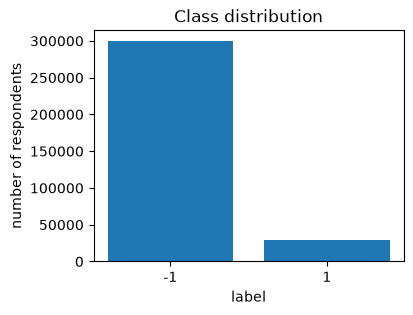

In [9]:
labels, counts = np.unique(y_train, return_counts=True)
for label, count in zip(labels, counts):
    print(f"label {label:+.0f}: {count:7d} ({count / y_train.size:.2%})")

y01 = (y_train == 1).astype(float)  # 0/1 version, convenient for rates

plt.figure(figsize=(4, 3))
plt.bar([str(int(l)) for l in labels], counts)
plt.xlabel("label")
plt.ylabel("number of respondents")
plt.title("Class distribution")
plt.show()

The dataset is **highly imbalanced**: only about 9% of respondents have MICHD. A classifier predicting always -1 would reach ~91% accuracy, so accuracy is not a good metric here. We should rather track the **F1 score** of the positive class and tune the decision threshold / class weights.

## Missing values

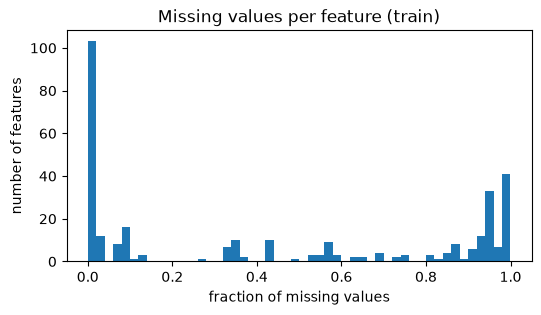

features with > 0% missing: 239
features with > 10% missing: 182
features with > 50% missing: 147
features with > 90% missing: 99
features with > 99% missing: 30

Largest difference of missing rate between train and test: 0.0040


In [10]:
missing_train = np.isnan(x_train).mean(axis=0)
missing_test = np.isnan(x_test).mean(axis=0)

plt.figure(figsize=(6, 3))
plt.hist(missing_train, bins=50)
plt.xlabel("fraction of missing values")
plt.ylabel("number of features")
plt.title("Missing values per feature (train)")
plt.show()

for thr in (0.0, 0.1, 0.5, 0.9, 0.99):
    print(f"features with > {thr:.0%} missing: {(missing_train > thr).sum()}")

print("\nLargest difference of missing rate between train and test:",
      f"{np.abs(missing_train - missing_test).max():.4f}")

In [11]:
order = np.argsort(missing_train)
print("Least missing features:")
for i in order[:10]:
    print(f"  {feature_names[i]:>10}: {missing_train[i]:.2%}")
print("Most missing features:")
for i in order[-10:]:
    print(f"  {feature_names[i]:>10}: {missing_train[i]:.2%}")

Least missing features:
      _STATE: 0.00%
    PERSDOC2: 0.00%
    HLTHPLN1: 0.00%
    MENTHLTH: 0.00%
    BLOODCHO: 0.00%
    CHCOCNCR: 0.00%
     ASTHMA3: 0.00%
    PAMISS1_: 0.00%
    CVDSTRK3: 0.00%
     EMPLOY1: 0.00%
Most missing features:
    ASACTLIM: 99.85%
    ASYMPTOM: 99.85%
    ASTHMED3: 99.85%
    ASINHALR: 99.85%
    ASNOSLEP: 99.90%
    ASDRVIST: 99.93%
    ASERVIST: 99.93%
    PCDMDECN: 99.95%
    COLGHOUS: 99.99%
      LADULT: 99.99%


Many features are almost entirely missing. This is mostly structural: BRFSS contains optional modules asked only in some states, and follow-up questions asked only for some previous answers (e.g. `SMOKDAY2` is only asked to people who answered yes to `SMOKE100`). A missing value is therefore often *informative*, which motivates adding missing-value indicators rather than only imputing.

We also check whether missingness itself is related to the target:

In [12]:
diffs = []
for j, name in enumerate(feature_names):
    miss = np.isnan(x_train[:, j])
    if 0.01 < miss.mean() < 0.99:
        diffs.append((y01[miss].mean() - y01[~miss].mean(), name))

diffs.sort(key=lambda t: abs(t[0]), reverse=True)
print("MICHD rate (missing) - MICHD rate (observed), largest gaps:")
for diff, name in diffs[:15]:
    print(f"  {name:>10}: {diff:+.3f}")

MICHD rate (missing) - MICHD rate (observed), largest gaps:
    DIABAGE2: -0.153
    CDDISCUS: -0.143
    CDSOCIAL: -0.143
    CDASSIST: -0.143
     CDHOUSE: -0.142
    BLDSUGAR: -0.140
     DIABEYE: -0.140
     DIABEDU: -0.140
     INSULIN: -0.140
    DOCTDIAB: -0.140
    CHKHEMO3: -0.140
     EYEEXAM: -0.140
    FEETCHK2: -0.140
     FEETCHK: -0.140
      BPMEDS: -0.125


In [20]:
for name in ["BPMEDS", "DIABAGE2"]:
    miss = np.isnan(col(name))
    print(
        f"{name}: missing for {miss.mean():.1%} of respondents | "
        f"MICHD rate {y01[miss].mean():.1%} if missing vs "
        f"{y01[~miss].mean():.1%} if answered"
    )

BPMEDS: missing for 59.8% of respondents | MICHD rate 3.8% if missing vs 16.3% if answered
DIABAGE2: missing for 87.1% of respondents | MICHD rate 6.9% if missing vs 22.1% if answered


## Categorical vs continuous features
We count the number of distinct finite values per feature. Features with few distinct values are very likely categorical (coded answers), the others continuous or ordinal counts.

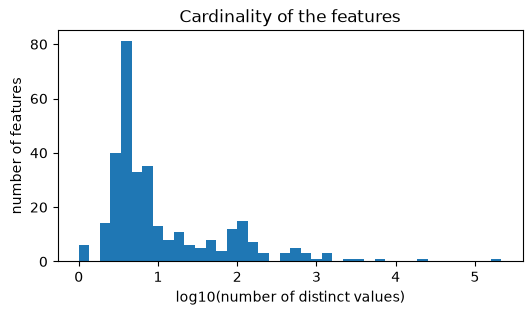

constant features: 6
categorical (<= 20 values): 241
continuous  (> 20 values): 80

Examples of high-cardinality features:
    PAMIN11_: 857 values
    _VEGESUM: 1024 values
      _STRWT: 1304 values
      _STSTR: 1306 values
    PA1VIGM_: 1373 values
     PA1MIN_: 2666 values
       _BMI5: 3524 values
    _WT2RAKE: 5528 values
    _CLLCPWT: 20445 values
     _LLCPWT: 216480 values


In [13]:
n_unique = np.array(
    [np.unique(x_train[np.isfinite(x_train[:, j]), j]).size for j in range(x_train.shape[1])]
)

plt.figure(figsize=(6, 3))
plt.hist(np.log10(np.maximum(n_unique, 1)), bins=40)
plt.xlabel("log10(number of distinct values)")
plt.ylabel("number of features")
plt.title("Cardinality of the features")
plt.show()

CATEGORICAL_THRESHOLD = 20
is_categorical = n_unique <= CATEGORICAL_THRESHOLD
print(f"constant features: {(n_unique <= 1).sum()}")
print(f"categorical (<= {CATEGORICAL_THRESHOLD} values): {is_categorical.sum()}")
print(f"continuous  (> {CATEGORICAL_THRESHOLD} values): {(~is_categorical).sum()}")
print("\nExamples of high-cardinality features:")
for j in np.argsort(n_unique)[-10:]:
    print(f"  {feature_names[j]:>10}: {n_unique[j]} values")

## Special codes in the raw answers
In BRFSS the raw answers use special codes: typically `7`/`9` (or `77`/`99`, `777`/`999`, ...) for *don't know* / *refused*, and `88`/`888` for *none*. Treating these codes as numbers would be meaningless (e.g. 99 days of poor health). Let's look at a few examples.

In [14]:
def value_counts(name, max_rows=15):
    """Print the distinct values of a feature with their counts and MICHD rate."""
    values = col(name)
    finite = np.isfinite(values)
    uniq, cnt = np.unique(values[finite], return_counts=True)
    print(f"{name}  (missing: {1 - finite.mean():.2%}, {uniq.size} distinct values)")
    for v, c in list(zip(uniq, cnt))[:max_rows]:
        rate = y01[finite][values[finite] == v].mean()
        print(f"   {v:>8g}: {c:7d}   MICHD rate {rate:.3f}")
    if uniq.size > max_rows:
        print("   ...")
    print()


value_counts("GENHLTH")   # 1 excellent ... 5 poor, 7 don't know, 9 refused
value_counts("SMOKE100")  # 1 yes, 2 no, 7 don't know, 9 refused

GENHLTH  (missing: 0.00%, 7 distinct values)
          1:   56937   MICHD rate 0.021
          2:  108089   MICHD rate 0.042
          3:  101880   MICHD rate 0.091
          4:   43349   MICHD rate 0.193
          5:   16992   MICHD rate 0.319
          7:     562   MICHD rate 0.171
          9:     324   MICHD rate 0.142

SMOKE100  (missing: 3.21%, 4 distinct values)
          1:  136828   MICHD rate 0.124
          2:  178357   MICHD rate 0.062
          7:    1332   MICHD rate 0.100
          9:    1077   MICHD rate 0.060



In [15]:
# PHYSHLTH: number of days of poor physical health in the last 30 days
# 1-30 = days, 88 = none, 77 = don't know, 99 = refused
values = col("PHYSHLTH")
for code_value, meaning in [(88, "none"), (77, "don't know"), (99, "refused")]:
    print(f"code {code_value} ({meaning}): {np.mean(values == code_value):.2%}")

# WEIGHT2: pounds (50-999), 9000-9998 = kilograms + 9000, 7777 / 9999 = unknown / refused
w = col("WEIGHT2")
print(f"\nWEIGHT2 in pounds: {np.mean((w >= 50) & (w < 1000)):.2%}")
print(f"WEIGHT2 in kg (9000+): {np.mean((w >= 9000) & (w < 9999)):.2%}")
print(f"WEIGHT2 unknown/refused: {np.mean((w == 7777) | (w == 9999)):.2%}")

code 88 (none): 62.25%
code 77 (don't know): 1.70%
code 99 (refused): 0.46%

WEIGHT2 in pounds: 92.78%
WEIGHT2 in kg (9000+): 0.21%
WEIGHT2 unknown/refused: 5.81%


These special codes confirm that the raw continuous-looking answers need cleaning (recode 88 → 0, 77/99 → missing, convert units) or, more simply, that we can rely on the **calculated variables** (`_BMI5`, `WTKG3`, `HTM4`, ...) where the CDC already did this work. One-hot encoding low-cardinality features also naturally handles the codes 7/9 as their own category.

## Distribution of some key features
We look at features that are known risk factors for cardiovascular disease: general health, age, sex, BMI, smoking, physical activity, blood pressure, cholesterol and diabetes. For categorical features we plot the MICHD rate per category.

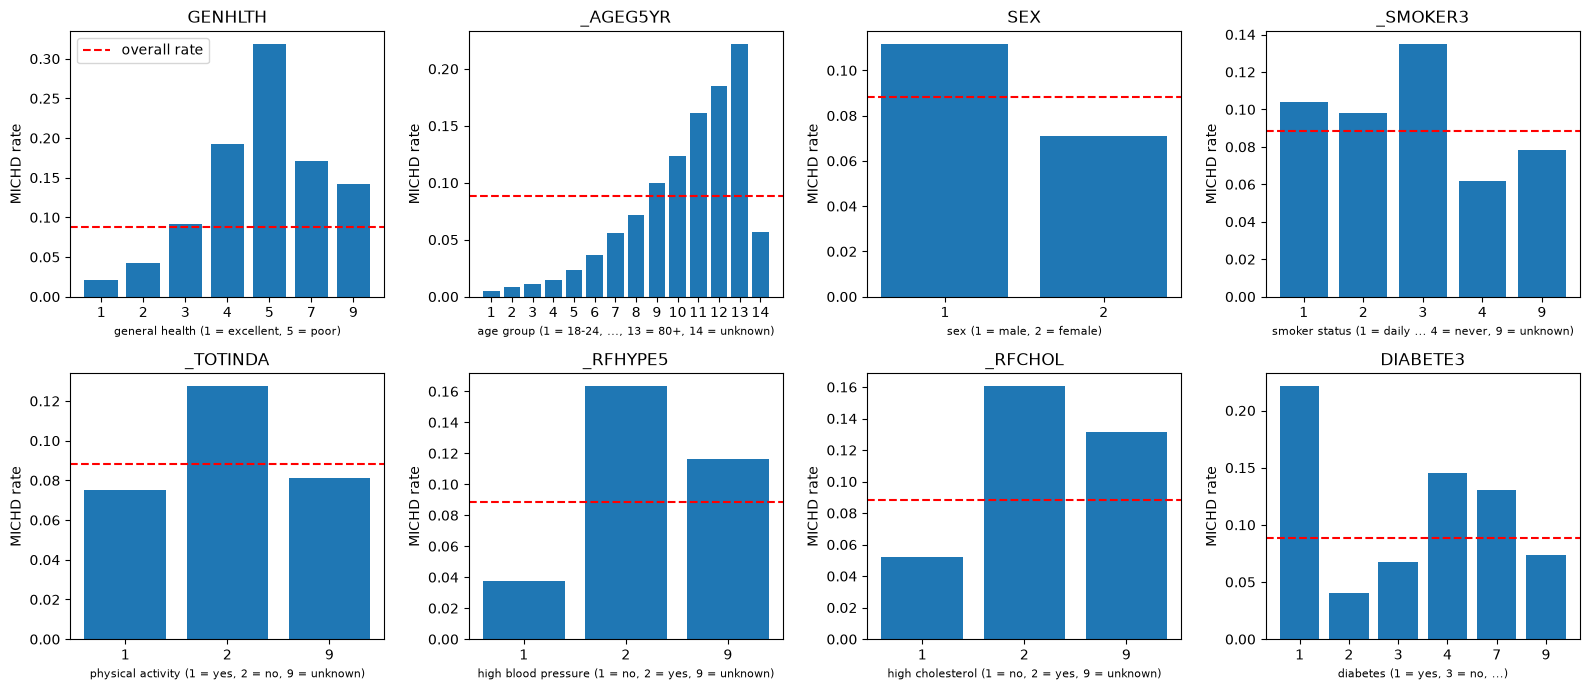

In [16]:
KEY_CATEGORICAL = {
    "GENHLTH": "general health (1 = excellent, 5 = poor)",
    "_AGEG5YR": "age group (1 = 18-24, ..., 13 = 80+, 14 = unknown)",
    "SEX": "sex (1 = male, 2 = female)",
    "_SMOKER3": "smoker status (1 = daily ... 4 = never, 9 = unknown)",
    "_TOTINDA": "physical activity (1 = yes, 2 = no, 9 = unknown)",
    "_RFHYPE5": "high blood pressure (1 = no, 2 = yes, 9 = unknown)",
    "_RFCHOL": "high cholesterol (1 = no, 2 = yes, 9 = unknown)",
    "DIABETE3": "diabetes (1 = yes, 3 = no, ...)",
}

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, (name, description) in zip(axes.ravel(), KEY_CATEGORICAL.items()):
    values = col(name)
    finite = np.isfinite(values)
    uniq = np.unique(values[finite])
    rates = [y01[finite][values[finite] == v].mean() for v in uniq]
    ax.bar([f"{v:g}" for v in uniq], rates)
    ax.axhline(y01.mean(), color="red", linestyle="--", label="overall rate")
    ax.set_title(name)
    ax.set_xlabel(description, fontsize=8)
    ax.set_ylabel("MICHD rate")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

Age show the cleanest relations so I want to highlight him in his own plot

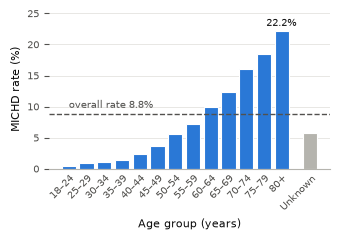

In [24]:
AGE_LABELS = {
    1: "18–24", 2: "25–29", 3: "30–34", 4: "35–39", 5: "40–44",
    6: "45–49", 7: "50–54", 8: "55–59", 9: "60–64", 10: "65–69",
    11: "70–74", 12: "75–79", 13: "80+", 14: "Unknown",
}
BAR = "#2a78d6"      # single series colour
UNKNOWN = "#b5b4ae"  # neutral grey for the "unknown" category
INK, MUTED = "#0b0b0b", "#52514e"

values = col("_AGEG5YR")
finite = np.isfinite(values)
codes = np.array(sorted(AGE_LABELS))
rates = np.array([y01[finite & (values == c)].mean() for c in codes])
overall = y01.mean()

# put "Unknown" slightly apart from the ordered age groups
x = np.arange(codes.size, dtype=float)
x[-1] += 0.6
colors = [BAR] * (codes.size - 1) + [UNKNOWN]

fig, ax = plt.subplots(figsize=(3.5, 2.5))  # width of one IEEE column
ax.bar(x, rates * 100, width=0.8, color=colors, edgecolor="white", linewidth=0.8)

# reference line, labelled directly instead of with a legend
ax.axhline(overall * 100, color=MUTED, linestyle="--", linewidth=1)
ax.text(0, overall * 100 + 0.6, f"overall rate {overall:.1%}",
        fontsize=7, color=MUTED, ha="left", va="bottom")

# label only the highest bar
top = np.argmax(rates)
ax.text(x[top], rates[top] * 100 + 0.4, f"{rates[top]:.1%}",
        fontsize=7, color=INK, ha="center", va="bottom")

ax.set_xticks(x, [AGE_LABELS[c] for c in codes], rotation=45, ha="right",
              rotation_mode="anchor", fontsize=7)
ax.set_xlabel("Age group (years)", fontsize=8, color=INK)
ax.set_ylabel("MICHD rate (%)", fontsize=8, color=INK)
ax.tick_params(axis="y", labelsize=7, colors=MUTED)
ax.tick_params(axis="x", colors=MUTED, length=0)
ax.set_ylim(0, rates.max() * 100 * 1.15)
ax.grid(axis="y", color="#e4e3df", linewidth=0.6)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#b5b4ae")

plt.tight_layout()
plt.savefig("figures/michd_by_age.pdf", bbox_inches="tight")
plt.show()

In [25]:
# print the michd rate for each age groups
for i, (label, rate) in enumerate(zip(codes, rates)):
    print(f"age group {AGE_LABELS[label]:>7}: {rate:.1%} MICHD rate")

age group   18–24: 0.5% MICHD rate
age group   25–29: 0.9% MICHD rate
age group   30–34: 1.1% MICHD rate
age group   35–39: 1.5% MICHD rate
age group   40–44: 2.3% MICHD rate
age group   45–49: 3.7% MICHD rate
age group   50–54: 5.6% MICHD rate
age group   55–59: 7.2% MICHD rate
age group   60–64: 10.0% MICHD rate
age group   65–69: 12.3% MICHD rate
age group   70–74: 16.1% MICHD rate
age group   75–79: 18.5% MICHD rate
age group     80+: 22.2% MICHD rate
age group Unknown: 5.7% MICHD rate


Fair or poor health        yes  22.8%   no   5.6%   ratio  4.1
Diabetes                   yes  22.1%   no   6.7%   ratio  3.3
High blood pressure        yes  16.3%   no   3.8%   ratio  4.4
High cholesterol           yes  16.1%   no   5.2%   ratio  3.1
Current or former smoker   yes  12.4%   no   6.2%   ratio  2.0
No physical activity       yes  12.7%   no   7.5%   ratio  1.7
Male                       yes  11.2%   no   7.1%   ratio  1.6


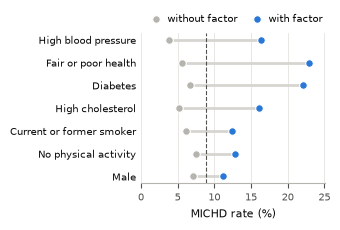

In [23]:
# (label, feature, codes of the "exposed" group, codes of the reference group)
# codes 7 / 9 ("don't know", "refused") are left out of both groups
RISK_FACTORS = [
    ("Fair or poor health", "GENHLTH", [4, 5], [1, 2, 3]),
    ("Diabetes", "DIABETE3", [1], [3]),
    ("High blood pressure", "_RFHYPE5", [2], [1]),
    ("High cholesterol", "_RFCHOL", [2], [1]),
    ("Current or former smoker", "_SMOKER3", [1, 2, 3], [4]),
    ("No physical activity", "_TOTINDA", [2], [1]),
    ("Male", "SEX", [1], [2]),
]
YES, NO = "#2a78d6", "#b5b4ae"
INK, MUTED = "#0b0b0b", "#52514e"

rows = []
for label, name, exposed, reference in RISK_FACTORS:
    values = col(name)
    rate_yes = y01[np.isin(values, exposed)].mean()
    rate_no = y01[np.isin(values, reference)].mean()
    rows.append((label, rate_yes, rate_no))
    print(f"{label:<26} yes {rate_yes:6.1%}   no {rate_no:6.1%}   "
          f"ratio {rate_yes / rate_no:4.1f}")

rows.sort(key=lambda r: r[1] / r[2])  # largest risk ratio at the top
labels = [r[0] for r in rows]
yes = np.array([r[1] for r in rows]) * 100
no = np.array([r[2] for r in rows]) * 100
y = np.arange(len(rows))

fig, ax = plt.subplots(figsize=(3.5, 2.4))  # one IEEE column
ax.hlines(y, no, yes, color="#d6d5d0", linewidth=2, zorder=1)
ax.scatter(no, y, s=30, color=NO, zorder=2, label="without factor",
           edgecolor="white", linewidth=0.8)
ax.scatter(yes, y, s=30, color=YES, zorder=3, label="with factor",
           edgecolor="white", linewidth=0.8)
ax.axvline(y01.mean() * 100, color=MUTED, linestyle="--", linewidth=0.8)

ax.set_yticks(y, labels, fontsize=7, color=INK)
ax.set_xlabel("MICHD rate (%)", fontsize=8, color=INK)
ax.tick_params(axis="x", labelsize=7, colors=MUTED)
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, max(yes.max(), no.max()) * 1.1)
ax.grid(axis="x", color="#e4e3df", linewidth=0.6)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#b5b4ae")
ax.legend(fontsize=7, frameon=False, ncol=2, loc="lower left",
          bbox_to_anchor=(-0.02, 1.0), handletextpad=0.2, columnspacing=1.0)

plt.tight_layout()
plt.savefig("figures/risk_factors.pdf", bbox_inches="tight")
plt.show()

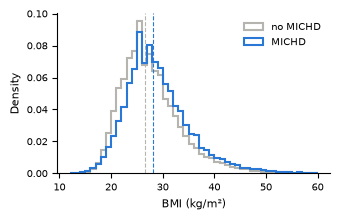

median BMI, no MICHD: 26.63
median BMI, MICHD: 28.12


In [29]:
bmi = col("_BMI5")
finite = np.isfinite(bmi)
bins = np.linspace(12, 60, 49)  # 1 kg/m² wide bins

fig, ax = plt.subplots(figsize=(3.5, 2.3))
for label, mask, color in [
    ("no MICHD", y01 == 0, "#b5b4ae"),
    ("MICHD", y01 == 1, "#2a78d6"),
]:
    ax.hist(bmi[finite & mask], bins=bins, density=True,
            histtype="step", linewidth=1.5, color=color, label=label)
    ax.axvline(np.median(bmi[finite & mask]), color=color,
               linestyle="--", linewidth=0.8)

ax.set_xlabel("BMI (kg/m²)", fontsize=8)
ax.set_ylabel("Density", fontsize=8)
ax.tick_params(labelsize=7)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.savefig("bmi_by_class.pdf", bbox_inches="tight")
plt.show()

for label, mask in [("no MICHD", y01 == 0), ("MICHD", y01 == 1)]:
    print(f"median BMI, {label}: {np.median(bmi[finite & mask]):.2f}")

The MICHD rate increases strongly with age and with poorer self-reported general health, and is higher for men, smokers, inactive people, and people with high blood pressure, high cholesterol or diabetes. The BMI distributions of the two classes overlap a lot, with a slight shift towards higher BMI for MICHD. Heavy-tailed continuous features like this one should be standardized (and possibly clipped) before training linear models.

## Univariate association with the target
To rank features quickly we compute the Pearson correlation between each feature (missing values imputed by the median) and the 0/1 target. This only captures *linear* and *monotone* effects: a categorical feature with arbitrary codes can be very informative and still have a low correlation, so this ranking is only indicative.

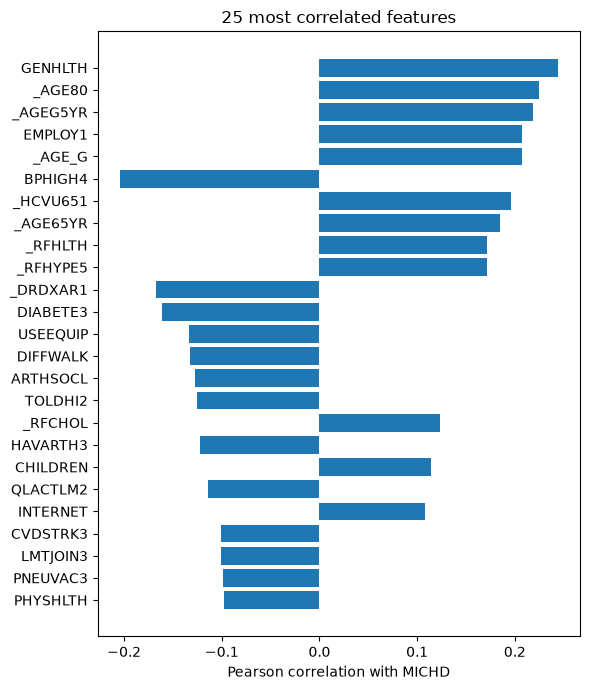

Correlation of administration features (should be small):
    _STATE: +0.006
    FMONTH: +0.007
     SEQNO: -0.050
   _LLCPWT: -0.048


In [18]:
correlations = np.zeros(len(feature_names))
for j in range(len(feature_names)):
    values = x_train[:, j]
    finite = np.isfinite(values)
    if finite.sum() < 2 or n_unique[j] <= 1:
        continue
    filled = np.where(finite, values, np.median(values[finite]))
    if filled.std() > 0:
        correlations[j] = np.corrcoef(filled, y01)[0, 1]

top = np.argsort(np.abs(correlations))[::-1][:25]
plt.figure(figsize=(6, 7))
plt.barh([feature_names[j] for j in top][::-1], correlations[top][::-1])
plt.xlabel("Pearson correlation with MICHD")
plt.title("25 most correlated features")
plt.tight_layout()
plt.show()

print("Correlation of administration features (should be small):")
for name in ["_STATE", "FMONTH", "SEQNO", "_LLCPWT"]:
    print(f"  {name:>8}: {correlations[feat_idx[name]]:+.3f}")

The most correlated features are age, general health, difficulty walking, blood pressure, cholesterol, diabetes and some other chronic conditions (stroke `CVDSTRK3`, COPD, arthritis, kidney disease). This matches the medical intuition. Administrative features have near-zero correlation, which justifies removing them.

## Redundant features
Calculated variables are often almost copies of raw ones (e.g. height in inches and in metres). We look for pairs of continuous features with very high correlation, on a random subsample for speed.

In [19]:
rng = np.random.default_rng(0)
sample = rng.choice(x_train.shape[0], size=20000, replace=False)
cont_idx = np.where((~is_categorical) & (missing_train < 0.5))[0]

xs = x_train[np.ix_(sample, cont_idx)].copy()
for k in range(xs.shape[1]):
    finite = np.isfinite(xs[:, k])
    xs[~finite, k] = np.median(xs[finite, k]) if finite.any() else 0.0

non_constant = xs.std(axis=0) > 0
xs = xs[:, non_constant]
kept_names = [feature_names[j] for j in cont_idx[non_constant]]
corr = np.corrcoef(xs, rowvar=False)

pairs = []
for a in range(len(kept_names)):
    for b in range(a + 1, len(kept_names)):
        if abs(corr[a, b]) > 0.95:
            pairs.append((corr[a, b], kept_names[a], kept_names[b]))

pairs.sort(key=lambda t: -abs(t[0]))
print(f"{len(pairs)} pairs of continuous features with |r| > 0.95:")
for r, a, b in pairs[:20]:
    print(f"  {a:>10} - {b:<10} r = {r:+.3f}")

5 pairs of continuous features with |r| > 0.95:
       SEQNO - _PSU       r = +1.000
      _STATE - _STSTR     r = +1.000
     MAXVO2_ - FC60_      r = +0.998
       HTIN4 - HTM4       r = +0.993
      _STRWT - _WT2RAKE   r = +0.952


Le'ts look what does perfectly correlated features correspond to :  

In [30]:
PAIRS = [
    ("SEQNO", "_PSU"),
    ("_STATE", "_STSTR"),
    ("MAXVO2_", "FC60_"),
    ("HTIN4", "HTM4"),
    ("_STRWT", "_WT2RAKE"),
]

for a, b in PAIRS:
    va, vb = col(a), col(b)
    both = np.isfinite(va) & np.isfinite(vb)
    print(f"=== {a} vs {b}  ({both.sum():,} rows with both values)")
    print(f"{'':>6}{a:>14}{b:>14}{'ratio':>10}")
    for i in np.where(both)[0][:8]:  # first 8 rows where both are present
        ratio = va[i] / vb[i] if vb[i] != 0 else np.nan
        print(f"{i:>6}{va[i]:>14.2f}{vb[i]:>14.2f}{ratio:>10.3f}")
    print(f"{'min':>6}{np.nanmin(va):>14.2f}{np.nanmin(vb):>14.2f}")
    print(f"{'max':>6}{np.nanmax(va):>14.2f}{np.nanmax(vb):>14.2f}")
    print()

=== SEQNO vs _PSU  (328,135 rows with both values)
               SEQNO          _PSU     ratio
     0 2015015680.00 2015015680.00     1.000
     1 2015004416.00 2015004416.00     1.000
     2 2015005696.00 2015005696.00     1.000
     3 2015004672.00 2015004672.00     1.000
     4 2015004672.00 2015004672.00     1.000
     5 2015004160.00 2015004160.00     1.000
     6 2015005568.00 2015005568.00     1.000
     7 2015000320.00 2015000320.00     1.000
   min 2015000064.00 2015000064.00
   max 2015023232.00 2015023232.00

=== _STATE vs _STSTR  (328,135 rows with both values)
              _STATE        _STSTR     ratio
     0         53.00     532049.00     0.000
     1         33.00     331071.00     0.000
     2         20.00     201091.00     0.000
     3         42.00     422039.00     0.000
     4         24.00     241011.00     0.000
     5         54.00     542019.00     0.000
     6         39.00     391071.00     0.000
     7         44.00     441011.00     0.000
   min        

Using the BRFSS 2015 Codebook, here is what each of these variables means:
- `SEQNO`: Annual Sequence Number.
- `_PSU`: Primary Sampling Unit (equal to the Annual Sequence Number).
- `_STATE`: State FIPS Code.
- `_STSTR`: Sample Design Stratification Variable (a number that combines the values of `_STATE` (first characters), `_GEOSTR` and `_DENSTR2` (final character)).
- `_STRWT`: Stratum weight (number of records in a stratum (`NRECSTR`) divided by the number of records selected (`NRECSEL`)).
- `_WT2RAKE`: Design weight used in raking (stratum weight (`_STRWT`) multiplied by the raw weighting factor (`_RAWRAKE`)).
- `MAXVO2_`: Estimated Age-Gender Specific Maximum Oxygen Consumption.
- `FC60_`: Estimated Functional Capacity.
- `HTIN4` / `HTM4`: Height in inches / in meters.

Cell code to have some number in the preprocessing section of the report

In [31]:
from project_utils import Preprocessor

prep = Preprocessor(categorical_threshold=20).fit(x_train, feature_names)

n_missing = len(prep.numeric_missing_indices)
n_numeric = len(prep.numeric_columns)
n_onehot = sum(v.size + 1 for v in prep.categorical_values)
n_inter = sum(spec[2].shape[0] for spec in prep.interaction_specs)

print(f"missing-value indicators: {n_missing}")
print(f"continuous features:      {n_numeric}")
print(f"one-hot columns:          {n_onehot}  ({len(prep.categorical_columns)} categorical features)")
print(f"interaction columns:      {n_inter}")
print(f"D (without bias):         {prep.n_features_out - 1}")

missing-value indicators: 63
continuous features:      70
one-hot columns:          1447  (224 categorical features)
interaction columns:      672
D (without bias):         2252
